In [77]:
# Cell A - imports & config
import os, time, random, json
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from torch.amp import GradScaler, autocast

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Config (tune these)
SEQ_LEN = 8
BATCH_SIZE = 8
LR = 1e-4
EPOCHS = 30
PATIENCE = 6
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = "liveness_checkpoint_2.pth"

DATASET_PATH = r"D:\face_video"
FRAME_OUTPUT_PATH = os.path.join(DATASET_PATH, "frames")
CSV_PATH = os.path.join(DATASET_PATH, "real_and_fake.csv")

os.makedirs(FRAME_OUTPUT_PATH, exist_ok=True)
print("Device:", DEVICE)


Device: cuda


In [78]:
# Cell B - transforms and dataset
train_transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.ColorJitter(0.2,0.2,0.2,0.02)], p=0.5),
    transforms.RandomApply([transforms.GaussianBlur(3)], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class VideoDataset(Dataset):
    def __init__(self, df, seq_len=SEQ_LEN, transform=None):
        self.df = df.copy().reset_index(drop=True)
        self.seq_len = seq_len
        self.transform = transform

        unique_labels = sorted(self.df["label"].unique())
        self.label_map = {lab: idx for idx, lab in enumerate(unique_labels)}
        print("Label mapping:", self.label_map)

        grouped = self.df.groupby("video_id")["frame_path"].apply(list)
        self.videos = grouped.to_dict()
        labels = self.df.groupby("video_id")["label"].first().to_dict()
        self.labels = labels
        self.video_ids = list(self.videos.keys())

    def __len__(self):
        return len(self.video_ids)

    def __getitem__(self, idx):
        vid = self.video_ids[idx]
        frames = self.videos[vid]
        raw_label = self.labels[vid]
        label = self.label_map[raw_label]

        if len(frames) >= self.seq_len:
            idxs = np.linspace(0, len(frames) - 1, self.seq_len, dtype=int)
        else:
            idxs = np.random.choice(len(frames), self.seq_len, replace=True)

        selected = [frames[i] for i in idxs]
        imgs = []
        for fp in selected:
            try:
                img = Image.open(fp).convert("RGB")
                if self.transform:
                    img = self.transform(img)
                imgs.append(img)
            except Exception as e:
                # robust fallback
                imgs.append(torch.zeros(3,128,128))
        imgs = torch.stack(imgs)   # (T, C, H, W)
        # return (T,C,H,W) -> DataLoader collate -> (B,T,C,H,W)
        return imgs, torch.tensor(label, dtype=torch.long)


In [79]:
# Cell C - prepare df & dataloaders (by video)
df = pd.read_csv(CSV_PATH)
vids = df["video_id"].unique().tolist()
random.seed(42); random.shuffle(vids)
split_idx = int(0.8 * len(vids))
train_vids, test_vids = vids[:split_idx], vids[split_idx:]

train_df = df[df["video_id"].isin(train_vids)].reset_index(drop=True)
test_df  = df[df["video_id"].isin(test_vids)].reset_index(drop=True)

train_ds = VideoDataset(train_df, seq_len=SEQ_LEN, transform=train_transform)
test_ds  = VideoDataset(test_df, seq_len=SEQ_LEN, transform=val_transform)

# Weighted sampler by video: compute weight per sample based on video label frequency
video_labels = [train_ds.labels[vid] for vid in train_ds.video_ids]
# map label names to indices consistent with label_map:
label_to_idx = train_ds.label_map
video_label_idxs = [label_to_idx[l] for l in [train_ds.labels[vid] for vid in train_ds.video_ids]]
# Count per class:
class_counts = np.bincount(video_label_idxs)
class_weights = 1.0 / (class_counts + 1e-6)
sample_weights = [class_weights[idx] for idx in video_label_idxs]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

NUM_WORKERS = 4 if os.name != "nt" else 0
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)

print("Train videos:", len(train_ds), "Test videos:", len(test_ds))


Label mapping: {'attack': 0, 'real': 1}
Label mapping: {'attack': 0, 'real': 1}
Train videos: 64 Test videos: 16


In [80]:
# Cell D - model with dropout and helper functions
class CNN_LSTM(nn.Module):
    def __init__(self, hidden_size=128, num_classes=2, dropout_p=0.4):
        super().__init__()
        base = models.mobilenet_v2(weights="IMAGENET1K_V1")
        self.feature_extractor = base.features
        self.pool = nn.AdaptiveAvgPool2d((1,1))
        feat_dim = base.last_channel

        self.lstm = nn.LSTM(input_size=feat_dim, hidden_size=hidden_size, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout_p)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        x = x.view(B*T, C, H, W)
        feats = self.feature_extractor(x)
        feats = self.pool(feats).view(B, T, -1)
        out, _ = self.lstm(feats)
        out = self.dropout(out[:, -1, :])
        out = self.fc(out)
        return out

def freeze_backbone(model):
    for p in model.feature_extractor.parameters():
        p.requires_grad = False

def unfreeze_backbone(model):
    for p in model.feature_extractor.parameters():
        p.requires_grad = True


In [81]:
# Cell E - focal loss (optional)
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.ce = nn.CrossEntropyLoss(weight=weight, reduction='none')
        self.reduction = reduction

    def forward(self, input, target):
        logpt = -self.ce(input, target)  # negative loss per sample
        pt = torch.exp(logpt)
        loss = -((1-pt)**self.gamma) * logpt
        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss


In [82]:
# Cell F - training loop (resume safe)
def train_model(model, train_loader, val_loader, optimizer, criterion, scaler,
                epochs=EPOCHS, patience=PATIENCE, checkpoint_path=CHECKPOINT,
                freeze_epochs=2, start_epoch=0, best_val_loss=float("inf")):
    model.to(DEVICE)
    patience_counter = 0
    history = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}

    # freeze backbone initially
    freeze_backbone(model)

    # resume
    if os.path.exists(checkpoint_path):
        ckpt = torch.load(checkpoint_path, map_location=DEVICE)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        start_epoch = ckpt.get("epoch", 0) + 1
        best_val_loss = ckpt.get("best_val_loss", best_val_loss)
        print("Resumed from epoch", start_epoch)

    # freeze backbone initially
    freeze_backbone(model)
    scaler = scaler

    for epoch in range(start_epoch, epochs):
        model.train()
        if epoch == freeze_epochs:
            print("Unfreezing backbone for fine-tuning")
            unfreeze_backbone(model)

        running_loss = 0.0; correct = 0; total = 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=False)
        for imgs, labels in pbar:
            # imgs: (B, T, C, H, W) if collated properly
            imgs = imgs.to(DEVICE, non_blocking=True).float()
            labels = labels.to(DEVICE, non_blocking=True)
            optimizer.zero_grad()
            with autocast("cuda"):
                outputs = model(imgs)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * labels.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            pbar.set_postfix(loss=loss.item(), acc=correct/total)

        train_loss = running_loss / total
        train_acc  = correct / total

        # validation (per-video)
        model.eval()
        val_loss = 0.0; val_correct = 0; val_total = 0
        with torch.no_grad():
            for imgs, labels in tqdm(val_loader, desc="Val", leave=False):
                imgs = imgs.to(DEVICE).float()
                labels = labels.to(DEVICE)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * labels.size(0)
                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
        val_loss = val_loss / val_total
        val_acc = val_correct / val_total

        print(f"Epoch {epoch+1}: Train Loss {train_loss:.4f} Acc {train_acc:.4f} | Val Loss {val_loss:.4f} Acc {val_acc:.4f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # checkpoint includes epoch & best_val_loss for resume
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "best_val_loss": best_val_loss
            }, checkpoint_path)
            print("Checkpoint saved (improved).")
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered.")
                break

    return model, history


In [83]:
# Cell G - instantiate and run
model = CNN_LSTM(hidden_size=128, num_classes=len(train_ds.label_map), dropout_p=0.4).to(DEVICE)

# Check if checkpoint exists and load if available
start_epoch = 0
best_val_loss = float("inf")

# optimizer only for trainable params (backbone frozen so only head)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR, weight_decay=1e-4)

if os.path.exists(CHECKPOINT):
    ckpt = torch.load(CHECKPOINT, map_location=DEVICE)
    if "model_state" in ckpt:   # structured checkpoint
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt.get("optimizer_state", optimizer.state_dict()))
        start_epoch = ckpt.get("epoch", 0) + 1
        best_val_loss = ckpt.get("best_val_loss", best_val_loss)
        print("Resumed from structured checkpoint at epoch", start_epoch)
    elif "model" in ckpt:  # raw weights only
        model.load_state_dict(ckpt["model"])
        print("Loaded raw model weights only (no optimizer/epoch info).")
    else:
        print("Checkpoint does not contain expected keys. Starting fresh.")



# Start with frozen backbone; train head first
freeze_backbone(model)

# optimizer only for trainable params (backbone frozen so only head)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR, weight_decay=1e-4)
# compute class weights for videos:
video_labels_train = [train_ds.labels[vid] for vid in train_ds.video_ids]
label_idxs = [train_ds.label_map[l] for l in video_labels_train]
class_counts = np.bincount(label_idxs)
class_weights = torch.tensor((1.0 / (class_counts + 1e-6)), dtype=torch.float).to(DEVICE)
print("Class weights:", class_weights)
criterion = nn.CrossEntropyLoss(weight=class_weights)

scaler = GradScaler()  

model, history = train_model(model, train_loader, test_loader, optimizer, criterion, scaler,
                             epochs=EPOCHS, patience=PATIENCE, checkpoint_path=CHECKPOINT, 
                             freeze_epochs=2, start_epoch=start_epoch, best_val_loss=best_val_loss)



Class weights: tensor([1.0000e+06, 1.5625e-02], device='cuda:0')


Epoch 1: Train Loss 0.4985 Acc 0.8906 | Val Loss 0.2849 Acc 1.0000
Checkpoint saved (improved).


Epoch 2: Train Loss 0.2058 Acc 1.0000 | Val Loss 0.1269 Acc 1.0000
Checkpoint saved (improved).
Unfreezing backbone for fine-tuning


Epoch 3: Train Loss 0.1073 Acc 1.0000 | Val Loss 0.0635 Acc 1.0000
Checkpoint saved (improved).


Epoch 4: Train Loss 0.0563 Acc 1.0000 | Val Loss 0.0364 Acc 1.0000
Checkpoint saved (improved).


...

Epoch 26: Train Loss 0.0019 Acc 1.0000 | Val Loss 0.0020 Acc 1.0000
Checkpoint saved (improved).


Epoch 27: Train Loss 0.0023 Acc 1.0000 | Val Loss 0.0020 Acc 1.0000
Checkpoint saved (improved).


Epoch 28: Train Loss 0.0019 Acc 1.0000 | Val Loss 0.0019 Acc 1.0000
Checkpoint saved (improved).


Epoch 29: Train Loss 0.0019 Acc 1.0000 | Val Loss 0.0018 Acc 1.0000
Checkpoint saved (improved).


Epoch 30: Train Loss 0.0017 Acc 1.0000 | Val Loss 0.0018 Acc 1.0000
Checkpoint saved (improved).


Evaluating: 100%|██████████| 2/2 [00:02<00:00,  1.21s/it]

              precision    recall  f1-score   support

      attack       0.00      0.00      0.00         0
        real       1.00      1.00      1.00        16

    accuracy                           1.00        16
   macro avg       0.50      0.50      0.50        16
weighted avg       1.00      1.00      1.00        16




C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\metrics\_classification.py:1565

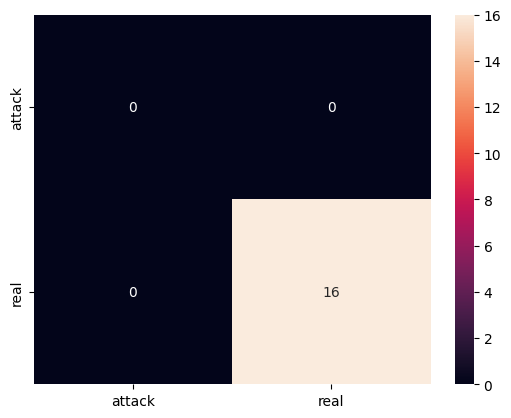

Anti-spoof metrics: {'APCER': np.float64(0.0), 'BPCER': np.float64(0.0), 'ACER': np.float64(0.0)}


In [ ]:
# Cell H - evaluation per-video (aggregate frame predictions to video decision)

ck = torch.load(CHECKPOINT, map_location=DEVICE)
model.load_state_dict(ck["model_state"])
model.to(DEVICE).eval()

y_true, y_pred = [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating"):
        imgs = imgs.to(DEVICE).float()
        labels = labels.to(DEVICE)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1)
        y_true.extend(labels.cpu().numpy().tolist())
        y_pred.extend(preds.cpu().numpy().tolist())

# Ensure labels and target_names match the label_map
labels = list(train_ds.label_map.values())
target_names = list(train_ds.label_map.keys())

print(classification_report(y_true, y_pred, labels=labels, target_names=target_names))
cm = confusion_matrix(y_true, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=target_names, yticklabels=target_names)
plt.show()

# APCER/BPCER/ACER (ensure label mapping)
def spoof_metrics(y_true, y_pred, positive_label_name="attack"):
    # positive_label_name is the spoof class name
    label_map = train_ds.label_map
    spoof_idx = label_map[positive_label_name]
    real_idx = [v for k,v in label_map.items() if k!=positive_label_name][0]
    cm = confusion_matrix(y_true, y_pred, labels=[real_idx, spoof_idx]).ravel()
    tn, fp, fn, tp = cm
    BPCER = fn / (tn + fn + 1e-8)
    APCER = fp / (fp + tp + 1e-8)
    ACER = (APCER + BPCER) / 2
    return {"APCER":APCER, "BPCER":BPCER, "ACER":ACER}

print("Anti-spoof metrics:", spoof_metrics(y_true, y_pred, positive_label_name="attack"))
